# Projeto C318 — Fundamentos de Machine Learning (Inatel)
## Tema 04: Crédito Consciente (Predição de Inadimplência em Cartão de Crédito)
**Docente:** Prof. Ricardo Augusto

### Contexto
Quem emite cartão de crédito ganha muito ao **antecipar** quais clientes vão atrasar a fatura no
próximo mês: dá para agir antes (lembrete, oferta de parcelamento, segurar aumento de limite) em
vez de apenas cobrar depois. Usamos a base pública **UCI Default of Credit Card Clients**: 30.000
clientes de um banco de Taiwan (abril a setembro de 2005), com limite de crédito, dados
demográficos, status de pagamento dos últimos 6 meses, valores das faturas e dos pagamentos. O
alvo indica se o cliente atrasou no mês seguinte (cerca de 22% atrasaram).

### Perguntas de negócio
1. Com o histórico dos últimos 6 meses, dá para prever quem vai atrasar no próximo mês? Quanto
   melhor isso é do que não usar modelo nenhum ("chute")?
2. O que mais leva ao calote?
3. Qual corte de decisão equilibra "deixar passar um caloteiro" e "incomodar um bom pagador"?
4. O modelo precisa de sexo, idade e estado civil para prever bem?

### Tipo de problema
**Classificação binária supervisionada** (o modelo aprende com exemplos rotulados de clientes que
pagaram ou não pagaram), com **classes desbalanceadas** (22% x 78%). Por isso a acurácia sozinha
engana (o "chute" acerta 78% sem identificar nenhum caloteiro); usamos ROC-AUC como critério
principal e recall, precisão e F1 da classe "inadimplente" como apoio.

### Roteiro e regra metodológica
1. Separação treino/teste (o teste fica guardado até o fim) · 2. EDA só no treino ·
3. Comparação justa por validação cruzada · 4. Hiperparâmetros com GridSearchCV ·
5. Atributos sensíveis · 6. Custo dos erros e corte · 7. Avaliação final no teste ·
8. Importância dos atributos · 9. Resultados (técnico e negócio) · 10. Limitações.

**Nenhuma informação do conjunto de teste influencia a escolha do modelo, dos hiperparâmetros,
dos atributos ou do corte.** O teste é usado uma única vez, na etapa 7 (e depois só para
interpretar o modelo já escolhido, na etapa 8).

### Como executar (a partir da raiz do projeto)
- Script: `python backend/analise_e_modelagem_c318.py` (grava `backend/modelo_credito.joblib`
  e as tabelas/gráficos em `resultados/`; cerca de 4 minutos).
- Variáveis opcionais: `MODEL_OUTPUT_PATH` (destino do artefato), `C318_RESULTADOS_DIR`
  (destino dos resultados), `C318_CSV_PATH` (outro CSV), `C318_MODO_RAPIDO=1` (grades mínimas e
  3 folds, para testes), `C318_N_JOBS` (paralelismo; padrão -1).
- Notebook: gerado a partir deste arquivo (fonte única), ver `notebooks/`.

In [1]:
import json
import os
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")

# ===========================================================================
# DECISÕES DO GRUPO (troque aqui; a evidência de cada uma é gerada abaixo)
# ===========================================================================
# Modelo de produção. None = regra automática: maior ROC-AUC média na validação cruzada;
# se a diferença para o segundo for menor que 1 desvio-padrão, desempata por F1 e depois
# por simplicidade. Para forçar: "Regressão Logística", "KNN", "Árvore de Decisão" ou
# "Random Forest".
MODELO_ESCOLHIDO = None

# Sexo, idade e estado civil (SEX, AGE, MARRIAGE). "auto" = regra padrão: se a queda de
# ROC-AUC sem esses atributos for menor que 1 desvio-padrão entre folds, o modelo de produção
# NÃO os usa. True/False forçam a decisão do grupo.
USAR_ATRIBUTOS_SENSIVEIS = "auto"

# Custo de cada tipo de erro. HIPÓTESE DIDÁTICA (não há dado real de custo na base):
# deixar passar um caloteiro (falso negativo) custa 3 vezes mais que incomodar um bom
# pagador (falso positivo). A sensibilidade a outras razões (1, 2, 3, 5 e 10) é mostrada.
CUSTO_FN = 3.0
CUSTO_FP = 1.0

# Corte de decisão (classe 1 se escore >= corte). None = corte que minimiza o custo total
# esperado na razão CUSTO_FN/CUSTO_FP, entre 0,10 e 0,90 (passo 0,05); ou um valor fixo.
LIMIAR_ESCOLHIDO = None

# ---------------------------------------------------------------------------
# Configuração de execução (reprodutível: semente fixa em tudo)
# ---------------------------------------------------------------------------
SEMENTE = 42
# C318_MODO_RAPIDO=1: grades mínimas e 3 folds (usado pelos testes automatizados)
MODO_RAPIDO = os.getenv("C318_MODO_RAPIDO") == "1"
N_FOLDS = 3 if MODO_RAPIDO else 5
N_JOBS = int(os.getenv("C318_N_JOBS", "-1"))


def _localizar_backend() -> Path:
    """Pasta backend/: a deste arquivo; em notebook (sem __file__), procura a partir da pasta atual."""
    if "__file__" in globals():
        return Path(__file__).resolve().parent
    for pasta in [Path.cwd(), *Path.cwd().parents]:
        if (pasta / "analise_e_modelagem_c318.py").is_file():
            return pasta
        if (pasta / "backend" / "analise_e_modelagem_c318.py").is_file():
            return pasta / "backend"
    return Path.cwd()


BASE_DIR = _localizar_backend()
RAIZ_REPO = BASE_DIR.parent
# Destino das tabelas e gráficos (configurável por C318_RESULTADOS_DIR)
RESULTADOS_DIR = Path(os.getenv("C318_RESULTADOS_DIR") or RAIZ_REPO / "resultados")
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)


def exibir_caminho(caminho: Path) -> str:
    """Caminho relativo à raiz do projeto quando possível (não expõe a pasta do usuário)."""
    try:
        return Path(caminho).resolve().relative_to(RAIZ_REPO).as_posix()
    except ValueError:
        return str(caminho)


def salvar_tabela(df: pd.DataFrame, nome: str) -> None:
    caminho = RESULTADOS_DIR / nome
    df.to_csv(caminho, index=False, encoding="utf-8")
    print(f"Tabela salva em: {exibir_caminho(caminho)}")


def salvar_figura(fig, nome: str) -> None:
    caminho = RESULTADOS_DIR / nome
    fig.savefig(caminho, dpi=150, bbox_inches="tight")
    print(f"Gráfico salvo em: {exibir_caminho(caminho)}")
    plt.show()
    plt.close(fig)

---
## 1. Coleta de Dados e Regra de Ouro da C318 (Separação Treino/Teste)
Antes de qualquer exploração ou ajuste estatístico, separamos $20\%$ do conjunto de dados para
**Teste** de forma estratificada (`stratify=y`, `random_state=42`), garantindo a mesma proporção
de inadimplentes ($\approx 22\%$) nos dois subconjuntos. Esses 6.000 clientes só serão usados na
avaliação final.

A limpeza de categorias abaixo é uma regra fixa linha a linha (não "aprende" nada dos dados),
por isso pode ser aplicada antes da divisão sem vazamento.

In [2]:
CSV_PATHS = [
    BASE_DIR / "UCI_Credit_Card.csv",
    RAIZ_REPO / "data" / "UCI_Credit_Card.csv",
    BASE_DIR / "data" / "UCI_Credit_Card.csv",
]

if os.getenv("C318_CSV_PATH"):  # caminho alternativo (usado pelo teste de vazamento)
    csv_encontrado = Path(os.environ["C318_CSV_PATH"]).resolve()
    if not csv_encontrado.is_file():
        raise FileNotFoundError(f"C318_CSV_PATH aponta para um arquivo inexistente: {csv_encontrado}")
else:
    csv_encontrado = next((p for p in CSV_PATHS if p.exists()), None)
    if not csv_encontrado:
        raise FileNotFoundError(
            "Arquivo 'UCI_Credit_Card.csv' não encontrado. Locais procurados: "
            + ", ".join(str(p) for p in CSV_PATHS)
        )

df_bruto = pd.read_csv(csv_encontrado)
print(f"Dataset carregado de: {exibir_caminho(csv_encontrado)}")
print(f"Dimensões originais: {df_bruto.shape[0]} linhas x {df_bruto.shape[1]} colunas")

# Definição das variáveis preditoras (X) e da variável resposta/alvo (y)
FEATURE_COLUMNS = [
    "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
]
TARGET_COLUMN = "default.payment.next.month"


def limpar_categorias_uci(df: pd.DataFrame) -> pd.DataFrame:
    """
    Trata categorias não documentadas na base pública da UCI:
    - EDUCATION: códigos 0, 5 e 6 são agrupados em 4 (Outros).
    - MARRIAGE: código 0 é agrupado em 3 (Outros).
    """
    df_clean = df.copy()
    df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({0: 3})
    return df_clean


df_limpo = limpar_categorias_uci(df_bruto)
X = df_limpo[FEATURE_COLUMNS]
y = df_limpo[TARGET_COLUMN]

# Separação imediata do conjunto de teste (20% teste = 6.000 clientes, 80% treino = 24.000 clientes)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMENTE, stratify=y
)

print(f"Conjunto de Treinamento: {X_train.shape[0]} clientes (Inadimplência: {y_train.mean()*100:.2f}%)")
print(f"Conjunto de Teste Isolado: {X_test.shape[0]} clientes (Inadimplência: {y_test.mean()*100:.2f}%)")

Dataset carregado de: data/UCI_Credit_Card.csv
Dimensões originais: 30000 linhas x 25 colunas
Conjunto de Treinamento: 24000 clientes (Inadimplência: 22.12%)
Conjunto de Teste Isolado: 6000 clientes (Inadimplência: 22.12%)


---
## 2. Análise Exploratória de Dados (EDA) sobre o Conjunto de Treinamento
Toda a EDA usa **somente os 24.000 clientes de treino**. Perguntas exploratórias:
1. Qual é o grau de desbalanceamento da variável alvo $y$?
2. Como o status de pagamento do mês mais recente (`PAY_0`) impacta a probabilidade de inadimplência?
3. Clientes com menores limites de crédito (`LIMIT_BAL`) apresentam maior taxa de atraso?
4. Quais variáveis se correlacionam com o atraso?
5. O histórico de atrasos dos outros meses (`PAY_2` a `PAY_6`) conta a mesma história?
   (A base não tem `PAY_1`: o mês mais recente chama-se `PAY_0`.)
6. Quem usa mais do limite atrasa mais?

Gráfico salvo em: resultados/eda_resumo.png


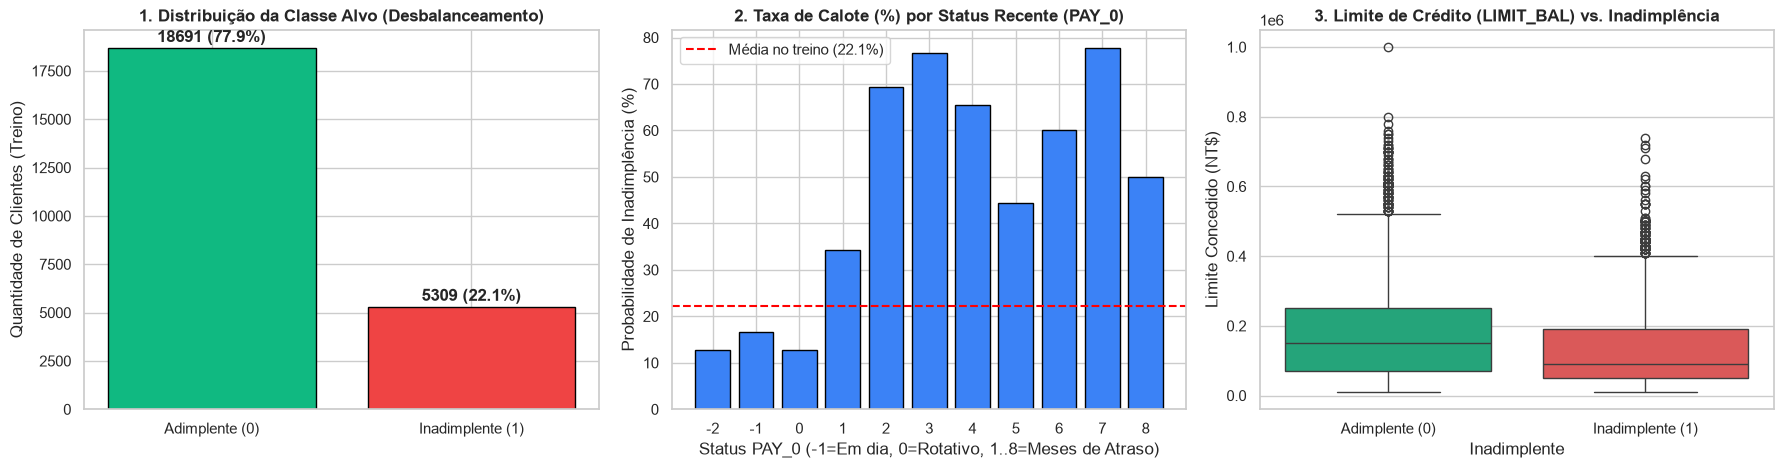

In [3]:
# Criamos um DataFrame combinando X_train e y_train apenas para gerar as visualizações da EDA
df_eda = X_train.copy()
df_eda["Inadimplente"] = y_train.values
taxa_media_treino = df_eda["Inadimplente"].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Desbalanceamento de Classes
contagem_classes = df_eda["Inadimplente"].value_counts().sort_index()
axes[0].bar(
    ["Adimplente (0)", "Inadimplente (1)"],
    contagem_classes.values,
    color=["#10b981", "#ef4444"],
    edgecolor="black",
)
axes[0].set_title("1. Distribuição da Classe Alvo (Desbalanceamento)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Quantidade de Clientes (Treino)")
for i, v in enumerate(contagem_classes.values):
    pct = (v / len(df_eda)) * 100
    axes[0].text(i, v + 300, f"{v} ({pct:.1f}%)", ha="center", fontweight="bold")

# Gráfico 2: Taxa de Inadimplência por Status de Pagamento Recente (PAY_0)
taxa_por_pay0 = df_eda.groupby("PAY_0")["Inadimplente"].mean() * 100
axes[1].bar(
    taxa_por_pay0.index.astype(str),
    taxa_por_pay0.values,
    color="#3b82f6",
    edgecolor="black",
)
axes[1].set_title("2. Taxa de Calote (%) por Status Recente (PAY_0)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Status PAY_0 (-1=Em dia, 0=Rotativo, 1..8=Meses de Atraso)")
axes[1].set_ylabel("Probabilidade de Inadimplência (%)")
axes[1].axhline(y=taxa_media_treino, color="red", linestyle="--",
                label=f"Média no treino ({taxa_media_treino:.1f}%)")
axes[1].legend()

# Gráfico 3: Distribuição do Limite de Crédito por Classe
sns.boxplot(
    data=df_eda,
    x="Inadimplente",
    y="LIMIT_BAL",
    hue="Inadimplente",
    palette=["#10b981", "#ef4444"],
    legend=False,
    ax=axes[2],
)
axes[2].set_title("3. Limite de Crédito (LIMIT_BAL) vs. Inadimplência", fontsize=12, fontweight="bold")
axes[2].set_xticks([0, 1], ["Adimplente (0)", "Inadimplente (1)"])
axes[2].set_ylabel("Limite Concedido (NT$)")

plt.tight_layout()
salvar_figura(fig, "eda_resumo.png")

Gráfico salvo em: resultados/eda_correlacao.png


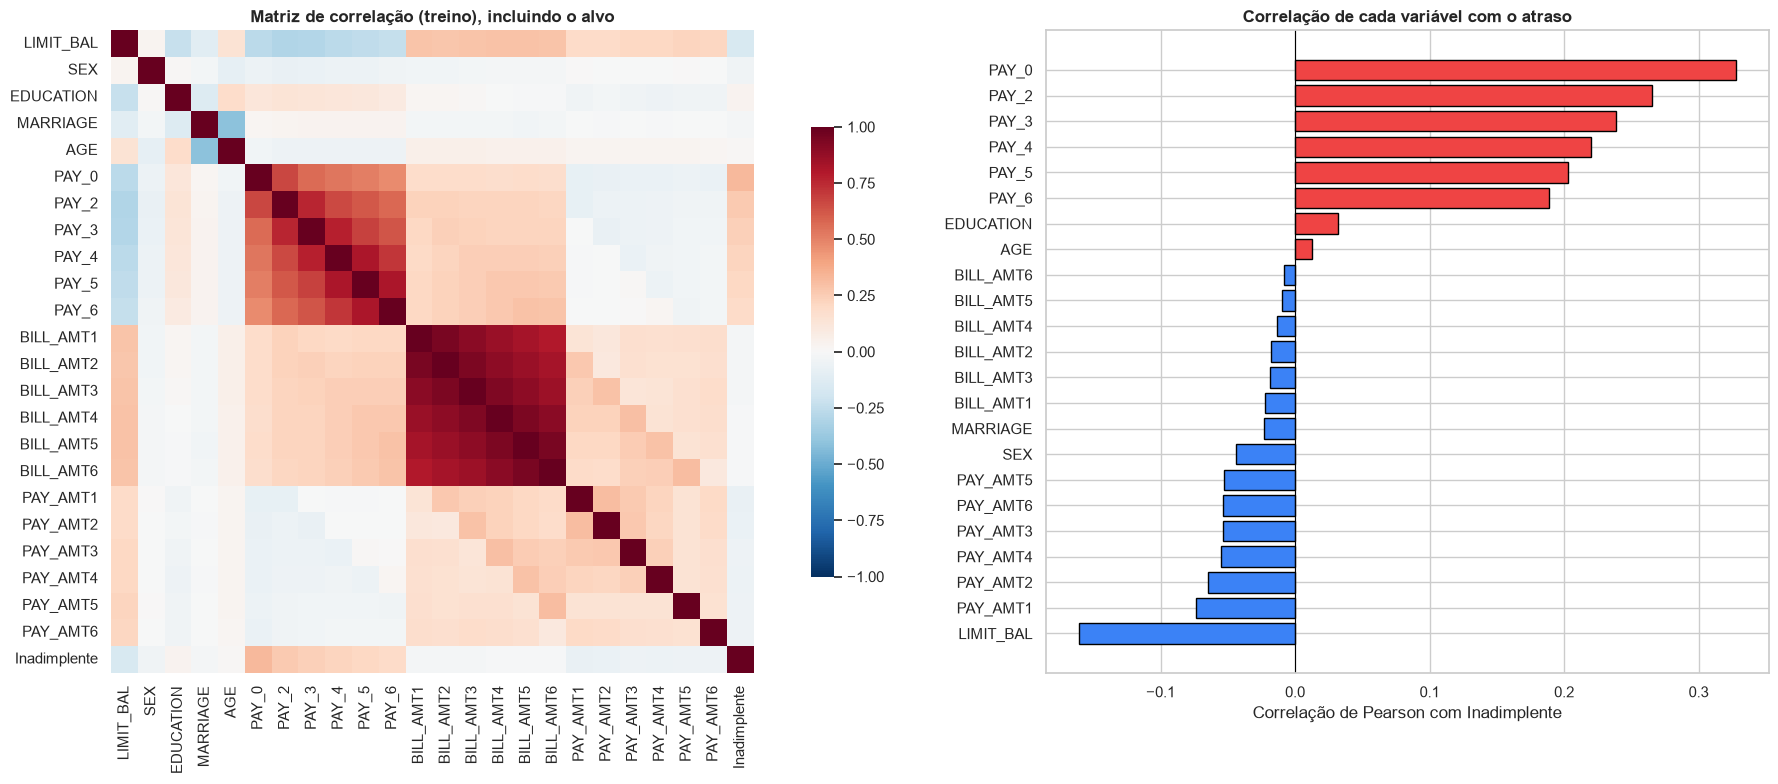

Maiores correlações (em módulo) com o atraso:
PAY_0        0.328
PAY_2        0.266
PAY_3        0.239
PAY_4        0.220
PAY_5        0.203
PAY_6        0.189
LIMIT_BAL   -0.161
PAY_AMT1    -0.073


In [4]:
# 4. Correlação (Pearson) entre as variáveis e com o alvo, somente no treino
correlacao = df_eda.corr(numeric_only=True)
corr_alvo = correlacao["Inadimplente"].drop("Inadimplente").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(correlacao, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7}, ax=axes[0])
axes[0].set_title("Matriz de correlação (treino), incluindo o alvo", fontsize=12, fontweight="bold")
axes[1].barh(corr_alvo.index, corr_alvo.values,
             color=["#ef4444" if v > 0 else "#3b82f6" for v in corr_alvo.values], edgecolor="black")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Correlação de cada variável com o atraso", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Correlação de Pearson com Inadimplente")
plt.tight_layout()
salvar_figura(fig, "eda_correlacao.png")
print("Maiores correlações (em módulo) com o atraso:")
print(corr_alvo.reindex(corr_alvo.abs().sort_values(ascending=False).index).head(8).round(3).to_string())

Gráfico salvo em: resultados/eda_status_pagamento.png


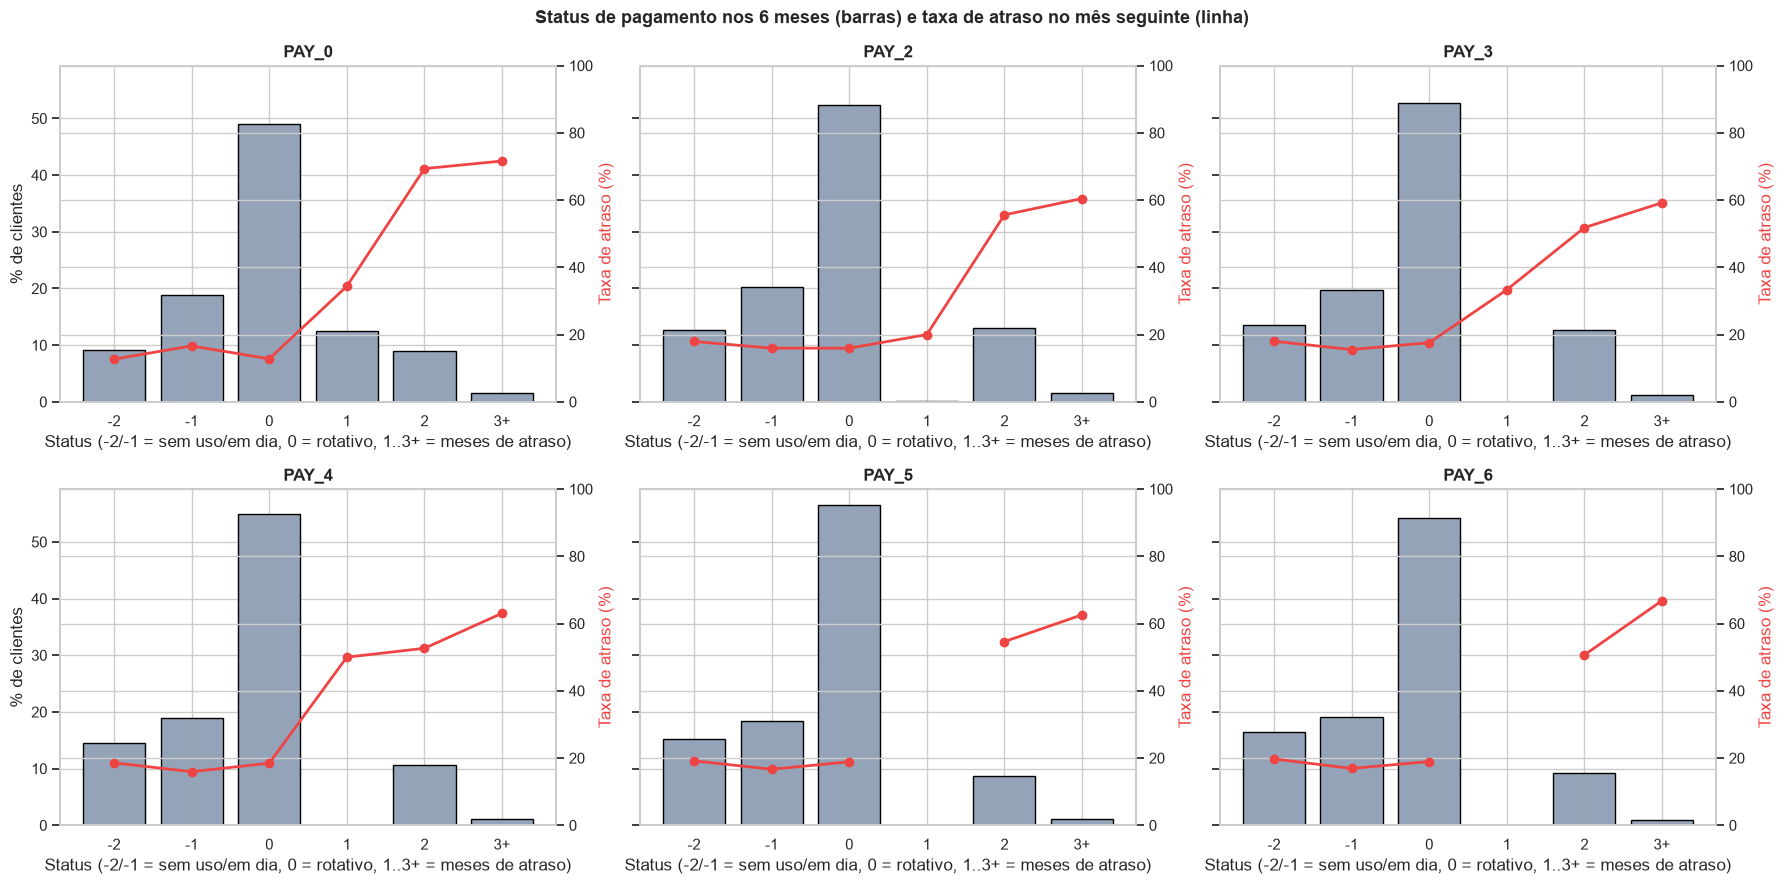

Taxa de atraso no mês seguinte: 50.4% entre quem já está atrasado em PAY_0 (>= 1 mês) x 13.7% entre quem está em dia ou no rotativo.


In [5]:
# 5. Distribuição do status de pagamento nos 6 meses e taxa de atraso por status
COLUNAS_PAY = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
ROTULOS_STATUS = ["-2", "-1", "0", "1", "2", "3+"]


def agrupar_status(serie: pd.Series) -> pd.Series:
    return serie.clip(upper=3).map(lambda v: "3+" if v == 3 else str(int(v)))


fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True)
for ax, coluna in zip(axes.ravel(), COLUNAS_PAY):
    status = agrupar_status(df_eda[coluna])
    freq = status.value_counts(normalize=True).reindex(ROTULOS_STATUS, fill_value=0) * 100
    taxa = df_eda.groupby(status)["Inadimplente"].mean().reindex(ROTULOS_STATUS) * 100
    ax.bar(ROTULOS_STATUS, freq.values, color="#94a3b8", edgecolor="black", label="% de clientes")
    ax.set_title(coluna, fontsize=12, fontweight="bold")
    ax.set_xlabel("Status (-2/-1 = sem uso/em dia, 0 = rotativo, 1..3+ = meses de atraso)")
    ax2 = ax.twinx()
    ax2.plot(ROTULOS_STATUS, taxa.values, color="#ef4444", marker="o", linewidth=2, label="taxa de atraso (%)")
    ax2.set_ylim(0, 100)
    ax2.set_ylabel("Taxa de atraso (%)", color="#ef4444")
axes[0, 0].set_ylabel("% de clientes")
axes[1, 0].set_ylabel("% de clientes")
fig.suptitle("Status de pagamento nos 6 meses (barras) e taxa de atraso no mês seguinte (linha)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
salvar_figura(fig, "eda_status_pagamento.png")
taxa_atrasado = df_eda.loc[df_eda["PAY_0"] >= 1, "Inadimplente"].mean()
taxa_em_dia = df_eda.loc[df_eda["PAY_0"] <= 0, "Inadimplente"].mean()
print(f"Taxa de atraso no mês seguinte: {taxa_atrasado:.1%} entre quem já está atrasado em PAY_0 "
      f"(>= 1 mês) x {taxa_em_dia:.1%} entre quem está em dia ou no rotativo.")

Gráfico salvo em: resultados/eda_uso_limite.png


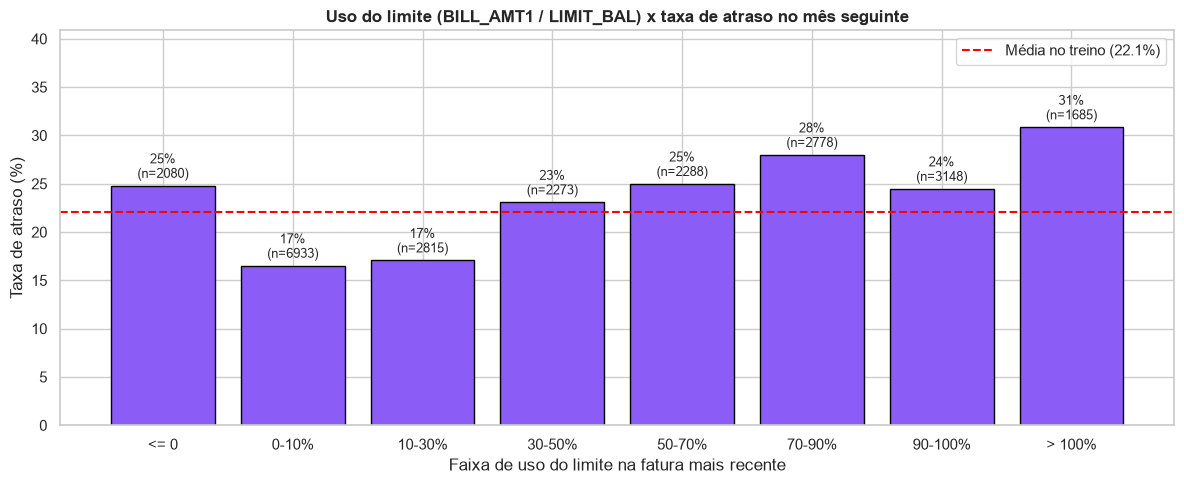

         taxa_atraso  clientes
<= 0           0.248      2080
0-10%          0.165      6933
10-30%         0.171      2815
30-50%         0.231      2273
50-70%         0.250      2288
70-90%         0.280      2778
90-100%        0.245      3148
> 100%         0.309      1685


In [6]:
# 6. Uso do limite (fatura mais recente / limite) e taxa de atraso
uso_limite = df_eda["BILL_AMT1"] / df_eda["LIMIT_BAL"]
faixas_uso = pd.cut(uso_limite, bins=[-np.inf, 0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, np.inf],
                    labels=["<= 0", "0-10%", "10-30%", "30-50%", "50-70%", "70-90%", "90-100%", "> 100%"])
resumo_uso = df_eda.groupby(faixas_uso, observed=False)["Inadimplente"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(resumo_uso.index.astype(str), resumo_uso["mean"] * 100, color="#8b5cf6", edgecolor="black")
for i, (taxa, n) in enumerate(zip(resumo_uso["mean"], resumo_uso["size"])):
    ax.text(i, taxa * 100 + 0.8, f"{taxa:.0%}\n(n={n})", ha="center", fontsize=9)
ax.axhline(taxa_media_treino, color="red", linestyle="--", label=f"Média no treino ({taxa_media_treino:.1f}%)")
ax.set_title("Uso do limite (BILL_AMT1 / LIMIT_BAL) x taxa de atraso no mês seguinte",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Faixa de uso do limite na fatura mais recente")
ax.set_ylabel("Taxa de atraso (%)")
ax.set_ylim(0, max(resumo_uso["mean"]) * 100 + 10)
ax.legend()
plt.tight_layout()
salvar_figura(fig, "eda_uso_limite.png")
print((resumo_uso.rename(columns={"mean": "taxa_atraso", "size": "clientes"})
       .assign(taxa_atraso=lambda d: d["taxa_atraso"].round(3))).to_string())

---
## 3. Comparação justa de modelos por validação cruzada (somente treino)
Todos os modelos usam **o mesmo pré-processamento dentro de um `Pipeline`** (padronização das
variáveis numéricas e *one-hot* das categóricas). Como o `Pipeline` inteiro é ajustado dentro de
cada *fold*, o `StandardScaler` e o `OneHotEncoder` nunca veem os dados de validação daquele fold
(sem vazamento).

Modelos comparados:
1. **Chute (referência):** `DummyClassifier(strategy="most_frequent")`, sempre prevê "vai pagar".
   Qualquer modelo útil precisa superá-lo.
2. **Regressão Logística:** aprendizagem baseada em modelos (fronteira linear).
3. **K-NN:** aprendizagem baseada em instâncias (similaridade por distância).
4. **Árvore de Decisão:** modelo não linear interpretável (regras "se... então").
5. **Random Forest:** *ensemble* de árvores de decisão.

Todos os que aceitam `class_weight` usam `"balanced"` (compensa os ~22% de inadimplentes).

**Limitação do KNN:** o `KNeighborsClassifier` não aceita `class_weight`, então ele é o único sem
compensação do desbalanceamento. Isso afeta principalmente as métricas que dependem do corte de
0,50 (recall, precisão e F1). Por isso o **critério principal de comparação é a ROC-AUC**, que
avalia a ordenação dos clientes por risco em todos os cortes possíveis e não depende do corte
nem do balanceamento das classes. Recall, precisão, F1 (classe 1) e PR-AUC são reportados como
apoio.

Validação: `StratifiedKFold(5, shuffle=True, random_state=42)` sobre `X_train`/`y_train`
(3 folds no modo rápido).

In [7]:
COLUNAS_CATEGORICAS = ["SEX", "EDUCATION", "MARRIAGE"]
COLUNAS_NUMERICAS = [col for col in FEATURE_COLUMNS if col not in COLUNAS_CATEGORICAS]

CHUTE = "Chute (referência)"
LOGISTICA = "Regressão Logística"
KNN = "KNN"
ARVORE = "Árvore de Decisão"
FLORESTA = "Random Forest"
MODELOS = [CHUTE, LOGISTICA, KNN, ARVORE, FLORESTA]

CV = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMENTE)
METRICAS_CV = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": make_scorer(recall_score, zero_division=0),
    "precisao": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}


ATRIBUTOS_SENSIVEIS = ["SEX", "AGE", "MARRIAGE"]


def criar_preprocessador(usar_sensiveis: bool = True) -> ColumnTransformer:
    """
    Mesmo pré-processamento para todos os modelos. Sem os atributos sensíveis, eles são
    descartados DENTRO do ColumnTransformer: a entrada continua com as 23 colunas (contrato
    da API), mas SEX, AGE e MARRIAGE não chegam ao classificador.
    """
    removidos = [] if usar_sensiveis else ATRIBUTOS_SENSIVEIS
    transformadores = [
        ("num", StandardScaler(), [c for c in COLUNAS_NUMERICAS if c not in removidos]),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         [c for c in COLUNAS_CATEGORICAS if c not in removidos]),
    ]
    if removidos:
        transformadores.append(("descartados", "drop", removidos))
    return ColumnTransformer(transformers=transformadores)


def criar_classificador(nome: str):
    """Configuração inicial de cada modelo (antes do GridSearchCV)."""
    if nome == CHUTE:
        return DummyClassifier(strategy="most_frequent")
    if nome == LOGISTICA:
        return LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEMENTE)
    if nome == KNN:
        # Não aceita class_weight (limitação registrada acima)
        return KNeighborsClassifier(n_neighbors=15, weights="distance")
    if nome == ARVORE:
        return DecisionTreeClassifier(class_weight="balanced", random_state=SEMENTE)
    if nome == FLORESTA:
        return RandomForestClassifier(
            n_estimators=120, max_depth=10, class_weight="balanced", random_state=SEMENTE
        )
    raise ValueError(f"modelo desconhecido: {nome}")


def criar_pipeline(nome: str, usar_sensiveis: bool = True) -> Pipeline:
    return Pipeline([
        ("preprocessador", criar_preprocessador(usar_sensiveis)),
        ("classificador", criar_classificador(nome)),
    ])


def resumir_cv(nome: str, resultado: dict) -> dict:
    """Média e desvio-padrão (amostral, entre folds) de cada métrica de cross_validate."""
    linha = {"modelo": nome}
    for metrica in METRICAS_CV:
        valores = np.asarray(resultado[f"test_{metrica}"])
        linha[f"{metrica}_media"] = valores.mean()
        linha[f"{metrica}_dp"] = valores.std(ddof=1)
    if "train_roc_auc" in resultado:
        linha["roc_auc_treino_media"] = np.mean(resultado["train_roc_auc"])
    linha["tempo_ajuste_s"] = np.mean(resultado["fit_time"])
    linha["tempo_predicao_s"] = np.mean(resultado["score_time"])
    return linha


# T1: configuração inicial, mesmo pré-processamento e mesma CV para todos (somente treino)
resultados_cv_inicial = {}
for nome in MODELOS:
    print(f"Validação cruzada (configuração inicial): {nome}...")
    resultados_cv_inicial[nome] = cross_validate(
        criar_pipeline(nome), X_train, y_train, cv=CV, scoring=METRICAS_CV,
        n_jobs=N_JOBS, return_train_score=True, error_score="raise",
    )

df_cv_inicial = pd.DataFrame([resumir_cv(n, r) for n, r in resultados_cv_inicial.items()])
print(f"\n=== VALIDAÇÃO CRUZADA NO TREINO ({N_FOLDS} folds), CONFIGURAÇÃO INICIAL ===")
print(df_cv_inicial.round(4).to_string(index=False))
salvar_tabela(df_cv_inicial.round(6), "comparacao_modelos_cv_inicial.csv")

Validação cruzada (configuração inicial): Chute (referência)...


Validação cruzada (configuração inicial): Regressão Logística...


Validação cruzada (configuração inicial): KNN...


Validação cruzada (configuração inicial): Árvore de Decisão...


Validação cruzada (configuração inicial): Random Forest...



=== VALIDAÇÃO CRUZADA NO TREINO (5 folds), CONFIGURAÇÃO INICIAL ===
             modelo  roc_auc_media  roc_auc_dp  pr_auc_media  pr_auc_dp  recall_media  recall_dp  precisao_media  precisao_dp  f1_media  f1_dp  roc_auc_treino_media  tempo_ajuste_s  tempo_predicao_s
 Chute (referência)         0.5000      0.0000        0.2212     0.0001        0.0000     0.0000          0.0000       0.0000    0.0000 0.0000                0.5000          0.1295            0.0255
Regressão Logística         0.7275      0.0127        0.5045     0.0145        0.6506     0.0183          0.3817       0.0123    0.4811 0.0130                0.7305          0.1929            0.0302
                KNN         0.7407      0.0064        0.4970     0.0097        0.3432     0.0088          0.6241       0.0179    0.4428 0.0115                1.0000          0.0646            1.0870
  Árvore de Decisão         0.6059      0.0100        0.2850     0.0082        0.3871     0.0201          0.3854       0.0133    0.3862

---
## 4. Hiperparâmetros com GridSearchCV (somente treino)
Em vez de valores "no olho" (K=15, profundidade 10), cada modelo (exceto o Chute) passa por um
`GridSearchCV` pequeno, com **a mesma validação cruzada** e `scoring="roc_auc"`. A tabela
completa da grade fica em `resultados/grid_search_resultados.csv`.

A configuração inicial da Árvore de Decisão (sem limite de profundidade) mostra por que isso
importa: ela decora o treino (AUC de treino 1,00) e generaliza mal na validação.

**Regra de escolha do vencedor:** maior ROC-AUC média na CV. Se a diferença para o segundo for
menor que 1 desvio-padrão (do líder, entre folds), os modelos são considerados empatados e o
desempate é pelo maior F1 e, persistindo o empate (diferença de F1 menor que 1 desvio-padrão),
pelo modelo mais simples.

In [8]:
if MODO_RAPIDO:
    GRADES = {
        LOGISTICA: {"classificador__C": [0.01, 1.0]},
        KNN: {"classificador__n_neighbors": [75], "classificador__weights": ["uniform"]},
        ARVORE: {"classificador__max_depth": [6], "classificador__min_samples_leaf": [50]},
        FLORESTA: {
            "classificador__n_estimators": [100],
            "classificador__max_depth": [10],
            "classificador__min_samples_leaf": [10],
        },
    }
else:
    GRADES = {
        LOGISTICA: {"classificador__C": [0.001, 0.01, 0.1, 1.0, 10.0]},
        KNN: {
            "classificador__n_neighbors": [35, 75, 151, 301],
            "classificador__weights": ["uniform", "distance"],
        },
        ARVORE: {
            "classificador__max_depth": [4, 6, 8, None],
            "classificador__min_samples_leaf": [50, 200, 500],
        },
        FLORESTA: {
            "classificador__n_estimators": [200, 500],
            "classificador__max_depth": [12, None],
            "classificador__min_samples_leaf": [10, 20, 40],
        },
    }

# Do mais simples ao mais complexo (critério final de desempate)
ORDEM_SIMPLICIDADE = [CHUTE, LOGISTICA, ARVORE, KNN, FLORESTA]


def executar_grid(pipeline: Pipeline, grade: dict, X_sel, y_sel):
    """
    GridSearchCV com a mesma CV e as mesmas métricas; escolhe pela ROC-AUC média.
    refit=False: a busca só escolhe; o ajuste final acontece depois, explicitamente.
    Retorna (tabela da grade, melhores parâmetros, linha da melhor combinação).
    """
    busca = GridSearchCV(
        pipeline, grade, scoring=METRICAS_CV, refit=False, cv=CV, n_jobs=N_JOBS, error_score="raise"
    )
    busca.fit(X_sel, y_sel)
    tabela = pd.DataFrame(busca.cv_results_)
    melhor = int(np.argmin(tabela["rank_test_roc_auc"].to_numpy()))
    return tabela, dict(tabela.loc[melhor, "params"]), tabela.loc[melhor]


def resumir_grid(nome: str, linha: pd.Series) -> dict:
    """Mesmo formato de resumir_cv, a partir da melhor linha de cv_results_."""
    resumo = {"modelo": nome}
    for metrica in METRICAS_CV:
        valores = np.array([linha[f"split{i}_test_{metrica}"] for i in range(N_FOLDS)])
        resumo[f"{metrica}_media"] = valores.mean()
        resumo[f"{metrica}_dp"] = valores.std(ddof=1)
    resumo["tempo_ajuste_s"] = linha["mean_fit_time"]
    resumo["tempo_predicao_s"] = linha["mean_score_time"]
    return resumo


def parametros_legiveis(parametros: dict) -> dict:
    """Remove o prefixo 'classificador__' e converte para tipos JSON."""
    return {
        k.replace("classificador__", ""): (v.item() if hasattr(v, "item") else v)
        for k, v in parametros.items()
    }


tabelas_grid, melhores_parametros, linhas_resumo = [], {}, []
linhas_resumo.append(resumir_cv(CHUTE, resultados_cv_inicial[CHUTE]))  # Chute não tem hiperparâmetros
for nome, grade in GRADES.items():
    print(f"GridSearchCV: {nome} ({int(np.prod([len(v) for v in grade.values()]))} combinações)...")
    tabela, parametros, melhor_linha = executar_grid(criar_pipeline(nome), grade, X_train, y_train)
    tabela.insert(0, "modelo", nome)
    tabelas_grid.append(tabela)
    melhores_parametros[nome] = parametros
    linhas_resumo.append(resumir_grid(nome, melhor_linha))
    print(f"   melhor: {parametros_legiveis(parametros)}  ROC-AUC = {melhor_linha['mean_test_roc_auc']:.4f}")

colunas_grid = (["modelo", "params"] + [f"mean_test_{m}" for m in METRICAS_CV]
                + [f"std_test_{m}" for m in METRICAS_CV] + ["rank_test_roc_auc", "mean_fit_time"])
df_grid = pd.concat(tabelas_grid, ignore_index=True)[colunas_grid]
df_grid["params"] = df_grid["params"].map(lambda p: str(parametros_legiveis(p)))
print("\n=== GRADE COMPLETA (ROC-AUC média na CV) ===")
print(df_grid[["modelo", "params", "mean_test_roc_auc", "std_test_roc_auc", "rank_test_roc_auc"]]
      .round(4).to_string(index=False))
salvar_tabela(df_grid.round(6), "grid_search_resultados.csv")

df_cv = pd.DataFrame(linhas_resumo).drop(columns="roc_auc_treino_media", errors="ignore")
df_cv["melhores_parametros"] = df_cv["modelo"].map(
    lambda n: str(parametros_legiveis(melhores_parametros.get(n, {})))
)

GridSearchCV: Regressão Logística (5 combinações)...


   melhor: {'C': 10.0}  ROC-AUC = 0.7276
GridSearchCV: KNN (8 combinações)...


   melhor: {'n_neighbors': 301, 'weights': 'uniform'}  ROC-AUC = 0.7592
GridSearchCV: Árvore de Decisão (12 combinações)...


   melhor: {'max_depth': 8, 'min_samples_leaf': 500}  ROC-AUC = 0.7645
GridSearchCV: Random Forest (12 combinações)...


   melhor: {'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 500}  ROC-AUC = 0.7857

=== GRADE COMPLETA (ROC-AUC média na CV) ===
             modelo                                                           params  mean_test_roc_auc  std_test_roc_auc  rank_test_roc_auc
Regressão Logística                                                     {'C': 0.001}             0.7241            0.0115                  5
Regressão Logística                                                      {'C': 0.01}             0.7269            0.0112                  4
Regressão Logística                                                       {'C': 0.1}             0.7275            0.0113                  3
Regressão Logística                                                       {'C': 1.0}             0.7275            0.0113                  2
Regressão Logística                                                      {'C': 10.0}             0.7276            0.0113                  1
              

In [9]:
def escolher_vencedor(df: pd.DataFrame):
    """Aplica a regra de escolha (ver texto acima). Retorna (nome, justificativa)."""
    candidatos = df[df["modelo"] != CHUTE].sort_values("roc_auc_media", ascending=False)
    lider, segundo = candidatos.iloc[0], candidatos.iloc[1]
    margem = lider["roc_auc_media"] - segundo["roc_auc_media"]
    if margem >= lider["roc_auc_dp"]:
        return lider["modelo"], (
            f"{lider['modelo']} tem a maior ROC-AUC média ({lider['roc_auc_media']:.4f}); a diferença "
            f"para o segundo, {segundo['modelo']} ({segundo['roc_auc_media']:.4f}), é {margem:.4f}, "
            f"maior que 1 desvio-padrão do líder ({lider['roc_auc_dp']:.4f}). Não há empate."
        )
    empatados = candidatos[candidatos["roc_auc_media"] > lider["roc_auc_media"] - lider["roc_auc_dp"]]
    por_f1 = empatados.sort_values("f1_media", ascending=False)
    melhor_f1, segundo_f1 = por_f1.iloc[0], por_f1.iloc[1]
    if melhor_f1["f1_media"] - segundo_f1["f1_media"] >= melhor_f1["f1_dp"]:
        return melhor_f1["modelo"], (
            f"Empate técnico na ROC-AUC (diferença menor que 1 desvio-padrão) entre "
            f"{', '.join(empatados['modelo'])}; desempate pelo maior F1: {melhor_f1['modelo']} "
            f"({melhor_f1['f1_media']:.4f})."
        )
    empatados_f1 = por_f1[por_f1["f1_media"] > melhor_f1["f1_media"] - melhor_f1["f1_dp"]]
    mais_simples = min(empatados_f1["modelo"], key=ORDEM_SIMPLICIDADE.index)
    return mais_simples, (
        f"Empate técnico na ROC-AUC e no F1 entre {', '.join(empatados_f1['modelo'])}; "
        f"desempate pela simplicidade: {mais_simples}."
    )


vencedor_regra, justificativa_vencedor = escolher_vencedor(df_cv)
modelo_vencedor_nome = MODELO_ESCOLHIDO or vencedor_regra
df_cv["vencedor"] = df_cv["modelo"] == modelo_vencedor_nome

print(f"\n=== COMPARAÇÃO FINAL NA CV ({N_FOLDS} folds, melhores hiperparâmetros) ===")
print(df_cv.drop(columns="melhores_parametros").round(4).to_string(index=False))
print(f"\nRegra automática: {justificativa_vencedor}")
if MODELO_ESCOLHIDO and MODELO_ESCOLHIDO != vencedor_regra:
    print(f"ATENÇÃO: o grupo forçou MODELO_ESCOLHIDO = {MODELO_ESCOLHIDO} (a regra indicaria {vencedor_regra}).")
print(f"Modelo vencedor: {modelo_vencedor_nome} {parametros_legiveis(melhores_parametros[modelo_vencedor_nome])}")
salvar_tabela(df_cv.round(6), "comparacao_modelos_cv.csv")


=== COMPARAÇÃO FINAL NA CV (5 folds, melhores hiperparâmetros) ===
             modelo  roc_auc_media  roc_auc_dp  pr_auc_media  pr_auc_dp  recall_media  recall_dp  precisao_media  precisao_dp  f1_media  f1_dp  tempo_ajuste_s  tempo_predicao_s  vencedor
 Chute (referência)         0.5000      0.0000        0.2212     0.0001        0.0000     0.0000          0.0000       0.0000    0.0000 0.0000          0.1295            0.0255     False
Regressão Logística         0.7276      0.0127        0.5045     0.0144        0.6508     0.0181          0.3815       0.0120    0.4809 0.0127          0.1513            0.0242     False
                KNN         0.7592      0.0094        0.5167     0.0160        0.2616     0.0113          0.6644       0.0374    0.3753 0.0163          0.0450            2.8989     False
  Árvore de Decisão         0.7645      0.0060        0.5224     0.0107        0.6316     0.0236          0.4472       0.0184    0.5233 0.0145          0.2638            0.0504     Fal

Gráfico salvo em: resultados/comparacao_modelos_cv.png


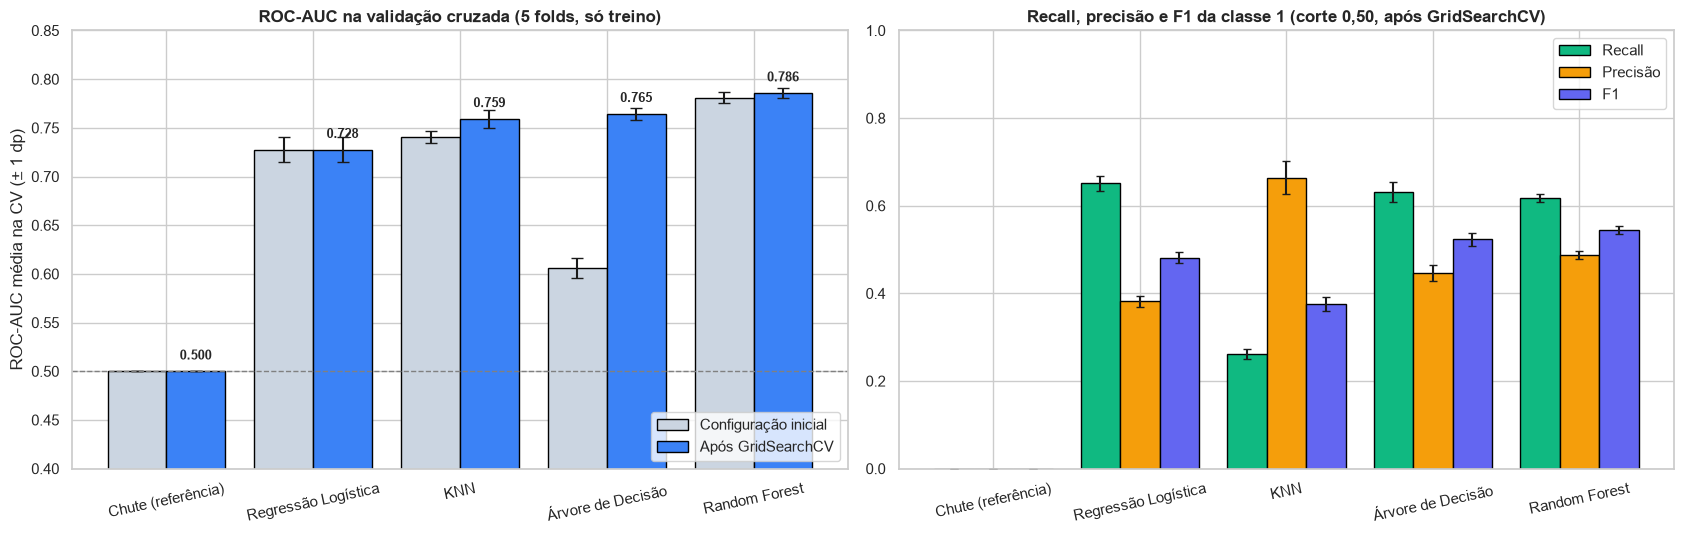

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
posicoes = np.arange(len(MODELOS))
inicial = df_cv_inicial.set_index("modelo").loc[MODELOS]
final = df_cv.set_index("modelo").loc[MODELOS]
axes[0].bar(posicoes - 0.2, inicial["roc_auc_media"], 0.4, yerr=inicial["roc_auc_dp"],
            color="#cbd5e1", edgecolor="black", capsize=4, label="Configuração inicial")
axes[0].bar(posicoes + 0.2, final["roc_auc_media"], 0.4, yerr=final["roc_auc_dp"],
            color="#3b82f6", edgecolor="black", capsize=4, label="Após GridSearchCV")
for x, v in zip(posicoes + 0.2, final["roc_auc_media"]):
    axes[0].text(x, v + 0.012, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
axes[0].axhline(0.5, color="gray", linestyle="--", linewidth=1)
axes[0].set_xticks(posicoes, MODELOS, rotation=12)
axes[0].set_ylim(0.4, 0.85)
axes[0].set_ylabel("ROC-AUC média na CV (± 1 dp)")
axes[0].set_title(f"ROC-AUC na validação cruzada ({N_FOLDS} folds, só treino)", fontsize=12, fontweight="bold")
axes[0].legend(loc="lower right")
largura = 0.27
for i, (metrica, cor) in enumerate([("recall", "#10b981"), ("precisao", "#f59e0b"), ("f1", "#6366f1")]):
    axes[1].bar(posicoes + (i - 1) * largura, final[f"{metrica}_media"], largura,
                yerr=final[f"{metrica}_dp"], color=cor, edgecolor="black", capsize=3,
                label={"recall": "Recall", "precisao": "Precisão", "f1": "F1"}[metrica])
axes[1].set_xticks(posicoes, MODELOS, rotation=12)
axes[1].set_ylim(0, 1)
axes[1].set_title("Recall, precisão e F1 da classe 1 (corte 0,50, após GridSearchCV)",
                  fontsize=12, fontweight="bold")
axes[1].legend()
plt.tight_layout()
salvar_figura(fig, "comparacao_modelos_cv.png")

resumo_hiperparametros = {
    "modo_rapido": MODO_RAPIDO,
    "n_folds": N_FOLDS,
    "criterio": "roc_auc",
    "modelos": {
        nome: {
            "grade": {k.replace("classificador__", ""): v for k, v in GRADES[nome].items()},
            "n_combinacoes": int(np.prod([len(v) for v in GRADES[nome].values()])),
            "melhores_parametros": parametros_legiveis(melhores_parametros[nome]),
            "roc_auc_media": round(float(df_cv.loc[df_cv["modelo"] == nome, "roc_auc_media"].iloc[0]), 6),
            "roc_auc_dp": round(float(df_cv.loc[df_cv["modelo"] == nome, "roc_auc_dp"].iloc[0]), 6),
        }
        for nome in GRADES
    },
    "vencedor": modelo_vencedor_nome,
    "vencedor_pela_regra": vencedor_regra,
    "justificativa": justificativa_vencedor,
}


def salvar_json(dados: dict, nome: str) -> None:
    caminho = RESULTADOS_DIR / nome
    caminho.write_text(json.dumps(dados, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Arquivo salvo em: {exibir_caminho(caminho)}")

---
## 5. Sexo, idade e estado civil: o modelo precisa deles?
A proposta do projeto fala em **uso responsável** dos dados. `SEX`, `AGE` e `MARRIAGE` são
características pessoais que não descrevem o comportamento de pagamento do cliente; usá-las para
decidir crédito pode reproduzir discriminações presentes nos dados históricos e é difícil de
justificar para o cliente e para um regulador. Por outro lado, retirá-las só se justifica se o
modelo não piorar de forma relevante.

**Experimento (somente treino):** a mesma validação cruzada do modelo vencedor, com os mesmos
hiperparâmetros, com e sem esses três atributos.

**Regra padrão:** se a queda de ROC-AUC sem eles for menor que 1 desvio-padrão entre folds
(variação natural do próprio modelo), a diferença não é relevante e o modelo de produção **não**
os usa. Nesse caso o `GridSearchCV` do vencedor é refeito sem eles, pois os melhores
hiperparâmetros podem mudar. Os atributos são descartados dentro do `ColumnTransformer`, então a
API continua recebendo as 23 colunas.

**Limitação:** retirar as colunas não garante um modelo justo. Outras variáveis (limite de
crédito, escolaridade) podem carregar parte da mesma informação. Uma auditoria de justiça por
grupo fica fora do escopo. A decisão final é do grupo (`USAR_ATRIBUTOS_SENSIVEIS` no topo).

In [11]:
def validar(pipeline: Pipeline) -> dict:
    """Validação cruzada no treino com a mesma CV e as mesmas métricas."""
    return cross_validate(pipeline, X_train, y_train, cv=CV, scoring=METRICAS_CV,
                          n_jobs=N_JOBS, error_score="raise")


parametros_vencedor = melhores_parametros[modelo_vencedor_nome]
cv_com = validar(criar_pipeline(modelo_vencedor_nome, True).set_params(**parametros_vencedor))
cv_sem = validar(criar_pipeline(modelo_vencedor_nome, False).set_params(**parametros_vencedor))

queda_auc = cv_com["test_roc_auc"].mean() - cv_sem["test_roc_auc"].mean()
dp_auc_com = cv_com["test_roc_auc"].std(ddof=1)
dif_pareada_auc = cv_com["test_roc_auc"] - cv_sem["test_roc_auc"]
dif_pareada_f1 = cv_com["test_f1"] - cv_sem["test_f1"]
dif_pareada_pr = cv_com["test_pr_auc"] - cv_sem["test_pr_auc"]
regra_usa_sensiveis = bool(queda_auc >= dp_auc_com)
if USAR_ATRIBUTOS_SENSIVEIS == "auto":
    usar_sensiveis = regra_usa_sensiveis
else:
    usar_sensiveis = bool(USAR_ATRIBUTOS_SENSIVEIS)


def linha_sensiveis(configuracao: str, resumo: dict) -> dict:
    resumo = dict(resumo)
    resumo.pop("modelo", None)
    return {"configuracao": configuracao, **resumo}


linhas_sensiveis = [
    linha_sensiveis("com SEX, AGE e MARRIAGE", resumir_cv("", cv_com)),
    linha_sensiveis("sem SEX, AGE e MARRIAGE (mesmos hiperparâmetros)", resumir_cv("", cv_sem)),
    {
        "configuracao": "diferença pareada por fold (com - sem)",
        "roc_auc_media": dif_pareada_auc.mean(), "roc_auc_dp": dif_pareada_auc.std(ddof=1),
        "pr_auc_media": dif_pareada_pr.mean(), "pr_auc_dp": dif_pareada_pr.std(ddof=1),
        "f1_media": dif_pareada_f1.mean(), "f1_dp": dif_pareada_f1.std(ddof=1),
    },
]

parametros_finais = parametros_vencedor
if not usar_sensiveis:
    print(f"Refazendo o GridSearchCV de {modelo_vencedor_nome} sem os atributos sensíveis...")
    _, parametros_finais, melhor_sem = executar_grid(
        criar_pipeline(modelo_vencedor_nome, False), GRADES[modelo_vencedor_nome], X_train, y_train
    )
    linhas_sensiveis.append(linha_sensiveis(
        f"sem SEX, AGE e MARRIAGE (GridSearchCV refeito: {parametros_legiveis(parametros_finais)})",
        resumir_grid("", melhor_sem),
    ))

df_sensiveis = pd.DataFrame(linhas_sensiveis)
print("\n=== COM vs SEM ATRIBUTOS SENSÍVEIS (CV no treino) ===")
print(df_sensiveis[["configuracao", "roc_auc_media", "roc_auc_dp", "f1_media", "f1_dp"]]
      .round(4).to_string(index=False))
salvar_tabela(df_sensiveis.round(6), "sensiveis_com_vs_sem.csv")

justificativa_sensiveis = (
    f"Sem SEX, AGE e MARRIAGE (mesmos hiperparâmetros), a ROC-AUC média na CV passou de "
    f"{cv_com['test_roc_auc'].mean():.4f} para {cv_sem['test_roc_auc'].mean():.4f} "
    f"(diferença com - sem: {round(queda_auc, 4) + 0.0:+.4f}); o desvio-padrão entre folds do modelo com os atributos é "
    f"{dp_auc_com:.4f}. O F1 passou de {cv_com['test_f1'].mean():.4f} para "
    f"{cv_sem['test_f1'].mean():.4f}. Diferença pareada por fold (com - sem): ROC-AUC "
    f"{dif_pareada_auc.mean():.4f} ± {dif_pareada_auc.std(ddof=1):.4f}. "
    + ("A queda é menor que 1 desvio-padrão: pela regra padrão, o modelo de produção NÃO usa "
       "esses atributos." if not regra_usa_sensiveis else
       "A queda é de pelo menos 1 desvio-padrão: pela regra padrão, o modelo de produção usa "
       "esses atributos.")
)
print("\n" + justificativa_sensiveis)
if USAR_ATRIBUTOS_SENSIVEIS != "auto" and usar_sensiveis != regra_usa_sensiveis:
    print(f"ATENÇÃO: o grupo forçou USAR_ATRIBUTOS_SENSIVEIS = {USAR_ATRIBUTOS_SENSIVEIS}.")
print(f"Atributos sensíveis usados no modelo de produção: {usar_sensiveis}")
print(f"Hiperparâmetros finais: {parametros_legiveis(parametros_finais)}")

resumo_hiperparametros["atributos_sensiveis"] = {
    "usados": usar_sensiveis,
    "regra_indicaria_usar": regra_usa_sensiveis,
    "justificativa": justificativa_sensiveis,
}
resumo_hiperparametros["final"] = {
    "modelo": modelo_vencedor_nome,
    "atributos_sensiveis_usados": usar_sensiveis,
    "parametros": parametros_legiveis(parametros_finais),
    "parametros_pipeline": {k: (v.item() if hasattr(v, "item") else v)
                            for k, v in parametros_finais.items()},
}
salvar_json(resumo_hiperparametros, "melhores_hiperparametros.json")

# Configuração final (ainda não ajustada): usada na escolha do corte e na avaliação final
pipeline_final_config = criar_pipeline(modelo_vencedor_nome, usar_sensiveis).set_params(**parametros_finais)

Refazendo o GridSearchCV de Random Forest sem os atributos sensíveis...



=== COM vs SEM ATRIBUTOS SENSÍVEIS (CV no treino) ===
                                                                                                    configuracao  roc_auc_media  roc_auc_dp  f1_media  f1_dp
                                                                                         com SEX, AGE e MARRIAGE         0.7857      0.0053    0.5448 0.0086
                                                                sem SEX, AGE e MARRIAGE (mesmos hiperparâmetros)         0.7845      0.0055    0.5438 0.0046
                                                                          diferença pareada por fold (com - sem)         0.0012      0.0009    0.0010 0.0042
sem SEX, AGE e MARRIAGE (GridSearchCV refeito: {'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 500})         0.7845      0.0055    0.5438 0.0046
Tabela salva em: resultados/sensiveis_com_vs_sem.csv

Sem SEX, AGE e MARRIAGE (mesmos hiperparâmetros), a ROC-AUC média na CV passou de 0.7857 para 0.7845 (dife

---
## 6. Custo dos erros e escolha do corte de decisão
O modelo devolve um escore entre 0 e 1; o **corte** transforma esse escore em decisão
("risco" se escore >= corte). Cada corte troca um tipo de erro pelo outro:
- **Falso negativo (FN):** o cliente vai atrasar e o modelo diz "vai pagar". O banco deixa passar
  um caloteiro e perde a chance de agir antes (renegociar, não aumentar o limite).
- **Falso positivo (FP):** o cliente vai pagar e o modelo diz "risco". O banco incomoda um bom
  pagador (contato desnecessário, limite segurado, cliente insatisfeito).

Custo total esperado de um corte: `CUSTO_FN × FN + CUSTO_FP × FP`. Não há dado real de custo
nesta base, então a razão **3 para 1** é uma **hipótese didática** (um FN custa 3 vezes um FP).
Por isso também mostramos qual seria o corte ótimo para as razões 1, 2, 3, 5 e 10.

**Sem usar o teste:** os escores vêm de `cross_val_predict` no treino (cada cliente do treino é
avaliado pelo modelo do fold em que ele ficou de fora), com a mesma validação cruzada e o
modelo já definido nas etapas anteriores.

In [12]:
proba_oof = cross_val_predict(
    pipeline_final_config, X_train, y_train, cv=CV, method="predict_proba", n_jobs=N_JOBS
)[:, 1]

RAZOES_CUSTO = [1, 2, 3, 5, 10]
RAZAO_BASE = CUSTO_FN / CUSTO_FP
CORTES = [round(c, 2) for c in np.arange(0.10, 0.90 + 1e-9, 0.05)]


def avaliar_corte(corte: float, y_real, escores) -> dict:
    pred = (escores >= corte).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    linha = {
        "limiar": corte,
        "recall": recall_score(y_real, pred, zero_division=0),
        "precisao": precision_score(y_real, pred, zero_division=0),
        "f1": f1_score(y_real, pred, zero_division=0),
        "VP": int(tp), "FP": int(fp), "FN": int(fn), "VN": int(tn),
        "custo_total": CUSTO_FN * fn + CUSTO_FP * fp,
    }
    for razao in RAZOES_CUSTO:
        linha[f"custo_razao_{razao}"] = razao * fn + fp  # em unidades de "custo de 1 FP"
    return linha


df_limiar = pd.DataFrame([avaliar_corte(c, y_train, proba_oof) for c in CORTES])
limiar_otimo_custo = float(df_limiar.loc[df_limiar["custo_total"].idxmin(), "limiar"])
LIMIAR = float(LIMIAR_ESCOLHIDO) if LIMIAR_ESCOLHIDO is not None else limiar_otimo_custo
if not np.isclose(df_limiar["limiar"], LIMIAR).any():  # corte forçado fora da grade
    df_limiar = (pd.concat([df_limiar, pd.DataFrame([avaliar_corte(LIMIAR, y_train, proba_oof)])])
                 .sort_values("limiar").reset_index(drop=True))
df_limiar["escolhido"] = np.isclose(df_limiar["limiar"], LIMIAR)
salvar_tabela(df_limiar.round(6), "limiar_custo.csv")

linhas_sensib = []
for razao in RAZOES_CUSTO:
    otimo = df_limiar.loc[df_limiar[f"custo_razao_{razao}"].idxmin()]
    linhas_sensib.append({
        "razao_custo_fn_fp": razao,
        "limiar_otimo": otimo["limiar"],
        "custo_minimo": otimo[f"custo_razao_{razao}"],
        "recall": otimo["recall"],
        "precisao": otimo["precisao"],
        "f1": otimo["f1"],
        "razao_base": np.isclose(razao, RAZAO_BASE),
    })
df_sensib_custo = pd.DataFrame(linhas_sensib)
salvar_tabela(df_sensib_custo.round(6), "limiar_sensibilidade_custo.csv")

print("=== CORTES AVALIADOS (predições fora-da-amostra no treino) ===")
print(df_limiar[["limiar", "recall", "precisao", "f1", "VP", "FP", "FN", "custo_total", "escolhido"]]
      .round(4).to_string(index=False))
print("\n=== SENSIBILIDADE À RAZÃO DE CUSTO FN:FP ===")
print(df_sensib_custo.round(4).to_string(index=False))
print(f"\nCorte que minimiza o custo na razão-base {RAZAO_BASE:g}:1 = {limiar_otimo_custo:.2f}")
if LIMIAR_ESCOLHIDO is not None and not np.isclose(LIMIAR, limiar_otimo_custo):
    print(f"ATENÇÃO: o grupo forçou LIMIAR_ESCOLHIDO = {LIMIAR:.2f}.")
print(f"Corte de decisão do modelo de produção: {LIMIAR:.2f}")

# Compatibilidade com a API: classificar_risco (main.py) começa o "Risco Moderado" em
# min(0,35; limiar). Com corte <= 0,35 essa faixa some e a API precisaria de faixas
# proporcionais ao limiar (ver ARTEFATO_MODELO.md).
INICIO_RISCO_MODERADO_API = 0.35
if LIMIAR <= INICIO_RISCO_MODERADO_API:
    print(f"ATENÇÃO: corte {LIMIAR:.2f} <= {INICIO_RISCO_MODERADO_API}: a faixa 'Risco Moderado' "
          "da API desaparece; ajuste classificar_risco em main.py antes de publicar este artefato.")
else:
    print(f"Faixas da API com este corte: Baixo < {INICIO_RISCO_MODERADO_API:.2f} <= Moderado "
          f"< {LIMIAR:.2f} <= Alto (classe 1 se e somente se Risco Alto).")

Tabela salva em: resultados/limiar_custo.csv
Tabela salva em: resultados/limiar_sensibilidade_custo.csv
=== CORTES AVALIADOS (predições fora-da-amostra no treino) ===
 limiar  recall  precisao     f1   VP    FP   FN  custo_total  escolhido
   0.10  0.9964    0.2261 0.3685 5290 18111   19      18168.0      False
   0.15  0.9853    0.2357 0.3805 5231 16958   78      17192.0      False
   0.20  0.9663    0.2522 0.4000 5130 15209  179      15746.0      False
   0.25  0.9367    0.2741 0.4241 4973 13171  336      14179.0      False
   0.30  0.8853    0.3037 0.4523 4700 10775  609      12602.0      False
   0.35  0.8130    0.3422 0.4817 4316  8296  993      11275.0      False
   0.40  0.7406    0.3889 0.5100 3932  6179 1377      10310.0      False
   0.45  0.6768    0.4392 0.5327 3593  4588 1716       9736.0      False
   0.50  0.6206    0.4838 0.5437 3295  3516 2014       9558.0       True
   0.55  0.5717    0.5192 0.5442 3035  2810 2274       9632.0      False
   0.60  0.5316    0.5555 0.54

Gráfico salvo em: resultados/curva_cortes.png


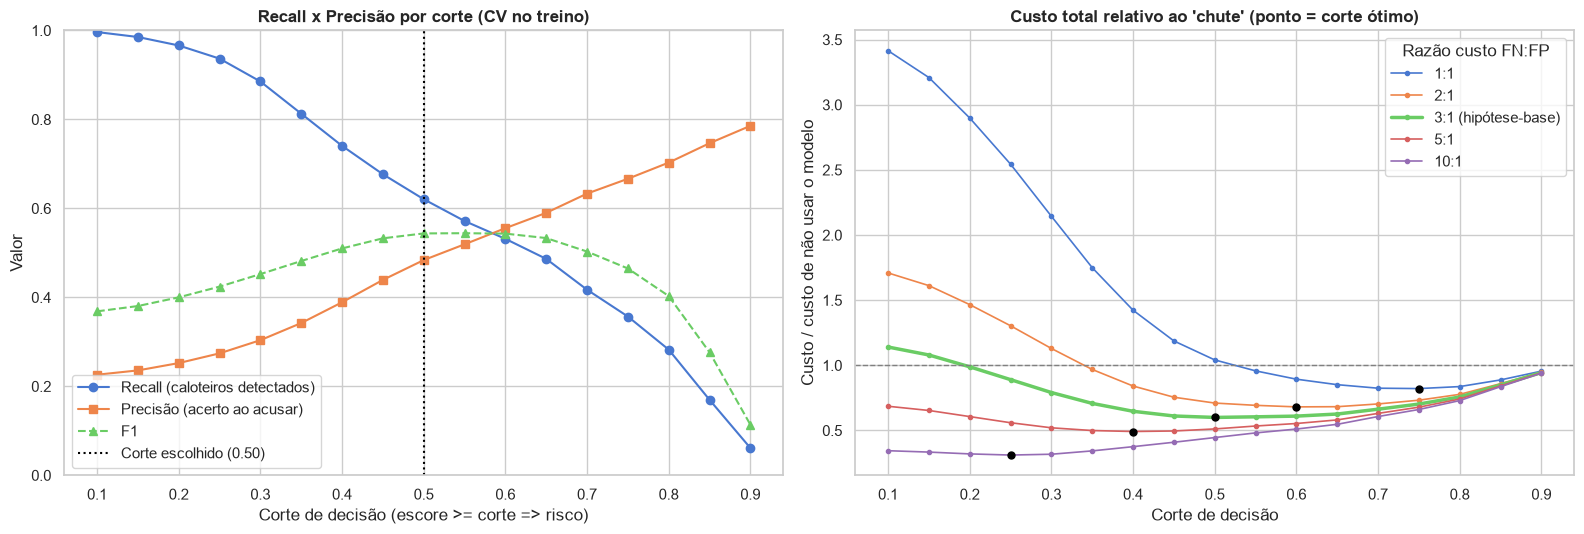

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].plot(df_limiar["limiar"], df_limiar["recall"], marker="o", label="Recall (caloteiros detectados)")
axes[0].plot(df_limiar["limiar"], df_limiar["precisao"], marker="s", label="Precisão (acerto ao acusar)")
axes[0].plot(df_limiar["limiar"], df_limiar["f1"], marker="^", linestyle="--", label="F1")
axes[0].axvline(LIMIAR, color="black", linestyle=":", label=f"Corte escolhido ({LIMIAR:.2f})")
axes[0].set_title("Recall x Precisão por corte (CV no treino)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Corte de decisão (escore >= corte => risco)")
axes[0].set_ylabel("Valor")
axes[0].set_ylim(0, 1)
axes[0].legend()

positivos = int(y_train.sum())
for razao in RAZOES_CUSTO:
    # Custo relativo a não usar modelo (ninguém marcado como risco: todos os caloteiros passam)
    relativo = df_limiar[f"custo_razao_{razao}"] / (razao * positivos)
    destaque = np.isclose(razao, RAZAO_BASE)
    axes[1].plot(df_limiar["limiar"], relativo, marker="o", markersize=3,
                 linewidth=2.5 if destaque else 1.2,
                 label=f"{razao}:1" + (" (hipótese-base)" if destaque else ""))
    i_min = relativo.idxmin()
    axes[1].scatter(df_limiar.loc[i_min, "limiar"], relativo[i_min], color="black", zorder=5, s=25)
axes[1].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Custo total relativo ao 'chute' (ponto = corte ótimo)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Corte de decisão")
axes[1].set_ylabel("Custo / custo de não usar o modelo")
axes[1].legend(title="Razão custo FN:FP")
plt.tight_layout()
salvar_figura(fig, "curva_cortes.png")

In [14]:
def br(valor: float, casas: int = 2) -> str:
    """Número com vírgula decimal (textos para o negócio)."""
    return f"{valor:.{casas}f}".replace(".", ",")


def descrever_corte(linha: pd.Series) -> str:
    return (f"recall {linha['recall']:.0%}, precisão {linha['precisao']:.0%}, "
            f"{int(linha['FN'])} caloteiros deixados passar e {int(linha['FP'])} bons pagadores incomodados")


linha_escolhida = df_limiar[df_limiar["escolhido"]].iloc[0]
vizinhos = df_limiar[np.isclose(df_limiar["limiar"], LIMIAR - 0.10) | np.isclose(df_limiar["limiar"], LIMIAR + 0.10)]
print(
    f"Para o negócio (validação cruzada no treino, {len(y_train)} clientes):\n"
    f"- Com o corte {br(LIMIAR)}, o modelo avisa {linha_escolhida['recall']:.0%} dos clientes que "
    f"de fato atrasam; de cada 10 clientes marcados como risco, {br(10 * linha_escolhida['precisao'], 1)} "
    f"atrasam de verdade.\n"
    f"- Em números: {int(linha_escolhida['VP'])} caloteiros detectados, {int(linha_escolhida['FN'])} "
    f"deixados passar e {int(linha_escolhida['FP'])} bons pagadores incomodados.\n"
    + "".join(f"- Para comparação, no corte {br(v['limiar'])}: {descrever_corte(v)}.\n"
              for _, v in vizinhos.iterrows())
    + f"- Baixar o corte detecta mais caloteiros, mas incomoda mais bons pagadores; subir o corte faz o "
    f"contrário. O corte escolhido é o de menor custo total supondo que deixar passar um caloteiro "
    f"custa {RAZAO_BASE:g} vezes mais que incomodar um bom pagador (hipótese a validar com a área de "
    f"crédito; ver a tabela de sensibilidade)."
)

Para o negócio (validação cruzada no treino, 24000 clientes):
- Com o corte 0,50, o modelo avisa 62% dos clientes que de fato atrasam; de cada 10 clientes marcados como risco, 4,8 atrasam de verdade.
- Em números: 3295 caloteiros detectados, 2014 deixados passar e 3516 bons pagadores incomodados.
- Para comparação, no corte 0,40: recall 74%, precisão 39%, 1377 caloteiros deixados passar e 6179 bons pagadores incomodados.
- Para comparação, no corte 0,60: recall 53%, precisão 56%, 2487 caloteiros deixados passar e 2258 bons pagadores incomodados.
- Baixar o corte detecta mais caloteiros, mas incomoda mais bons pagadores; subir o corte faz o contrário. O corte escolhido é o de menor custo total supondo que deixar passar um caloteiro custa 3 vezes mais que incomodar um bom pagador (hipótese a validar com a área de crédito; ver a tabela de sensibilidade).


---
## 7. Avaliação final no teste (uso único)
Modelo, hiperparâmetros, atributos e corte já foram escolhidos usando só o treino. Agora o modelo
final é treinado em todo o `X_train` e avaliado **uma única vez** nos 6.000 clientes de teste,
com o corte escolhido. As métricas gravadas no artefato usam esse mesmo corte, exatamente como a
API decide a classe (`classe 1 se escore >= corte`). O "chute" é avaliado no mesmo teste como
referência.

In [15]:
modelo_final = clone(pipeline_final_config).fit(X_train, y_train)
chute_final = criar_pipeline(CHUTE).fit(X_train, y_train)


def avaliar_no_teste(nome: str, pipeline: Pipeline) -> dict:
    escores = pipeline.predict_proba(X_test)[:, 1]
    pred = (escores >= LIMIAR).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {
        "modelo": nome,
        "limiar": LIMIAR,
        "acuracia": accuracy_score(y_test, pred),
        "precisao": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, escores),
        "pr_auc": average_precision_score(y_test, escores),
        "VP": int(tp), "VN": int(tn), "FP": int(fp), "FN": int(fn),
    }


# ---- Único uso do conjunto de teste para avaliação ----
aval_final = avaliar_no_teste(f"{modelo_vencedor_nome} (modelo final)", modelo_final)
aval_chute = avaliar_no_teste(CHUTE, chute_final)
df_teste = pd.DataFrame([aval_final, aval_chute])
print(f"=== AVALIAÇÃO FINAL NO TESTE ({len(y_test)} clientes, corte {LIMIAR:.2f}) ===")
print(df_teste.round(4).to_string(index=False))
salvar_tabela(df_teste.round(6), "avaliacao_teste.csv")

# ROC-AUC esperada pela CV (mesma configuração) x ROC-AUC obtida no teste
linha_cv_final = df_sensiveis.iloc[-1] if not usar_sensiveis else df_cv[df_cv["vencedor"]].iloc[0]
auc_cv_final = float(linha_cv_final["roc_auc_media"])
print(f"\nROC-AUC na CV do treino: {auc_cv_final:.4f} ± {linha_cv_final['roc_auc_dp']:.4f} | "
      f"ROC-AUC no teste: {aval_final['roc_auc']:.4f} | chute no teste: {aval_chute['roc_auc']:.4f}")

=== AVALIAÇÃO FINAL NO TESTE (6000 clientes, corte 0.50) ===
                      modelo  limiar  acuracia  precisao  recall     f1  roc_auc  pr_auc  VP   VN  FP   FN
Random Forest (modelo final)     0.5    0.7680    0.4805  0.6029 0.5348   0.7734  0.5486 800 3808 865  527
          Chute (referência)     0.5    0.7788    0.0000  0.0000 0.0000   0.5000  0.2212   0 4673   0 1327
Tabela salva em: resultados/avaliacao_teste.csv

ROC-AUC na CV do treino: 0.7845 ± 0.0055 | ROC-AUC no teste: 0.7734 | chute no teste: 0.5000


Gráfico salvo em: resultados/matriz_confusao_final.png


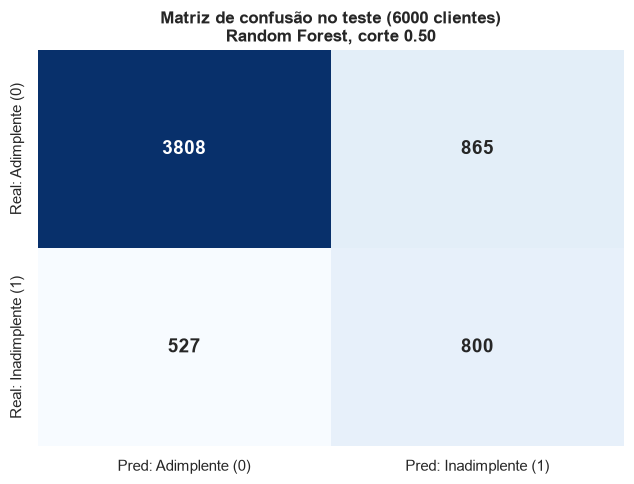

In [16]:
matriz = np.array([[aval_final["VN"], aval_final["FP"]], [aval_final["FN"], aval_final["VP"]]])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
    xticklabels=["Pred: Adimplente (0)", "Pred: Inadimplente (1)"],
    yticklabels=["Real: Adimplente (0)", "Real: Inadimplente (1)"],
    annot_kws={"size": 14, "weight": "bold"},
)
ax.set_title(f"Matriz de confusão no teste ({len(y_test)} clientes)\n"
             f"{modelo_vencedor_nome}, corte {LIMIAR:.2f}", fontsize=12, fontweight="bold")
plt.tight_layout()
salvar_figura(fig, "matriz_confusao_final.png")

In [17]:
# Métricas no formato consumido pela rota GET /metrics (mesmo corte usado pela API)
metricas_producao = {
    "algoritmo": f"{type(modelo_final[-1]).__name__} (Pipeline Scikit-Learn)",
    "total_amostras_teste": int(len(y_test)),
    "acuracia": round(float(aval_final["acuracia"]), 4),
    "precisao": round(float(aval_final["precisao"]), 4),
    "recall_sensibilidade": round(float(aval_final["recall"]), 4),
    "f1_score": round(float(aval_final["f1"]), 4),
    "matriz_confusao": {k: aval_final[k] for k in ("VP", "VN", "FP", "FN")},
    # Chaves adicionais (ignoradas pela API, usadas nos testes e na documentação)
    "roc_auc": round(float(aval_final["roc_auc"]), 4),
    "pr_auc": round(float(aval_final["pr_auc"]), 4),
    "roc_auc_chute": round(float(aval_chute["roc_auc"]), 4),
    "roc_auc_cv_treino": round(auc_cv_final, 4),
}

# Destino do artefato: backend/modelo_credito.joblib, ou a variável MODEL_OUTPUT_PATH.
# Contrato consumido pela API documentado em ARTEFATO_MODELO.md.
MODEL_OUTPUT_PATH = Path(os.getenv("MODEL_OUTPUT_PATH") or BASE_DIR / "modelo_credito.joblib")

metadados_artefato = {
    "sklearn_version": sklearn.__version__,
    "treinado_em": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "csv_origem": exibir_caminho(csv_encontrado),
    "limiar_decisao": LIMIAR,
    "atributos_sensiveis_usados": usar_sensiveis,
    "modelo": modelo_vencedor_nome,
    "hiperparametros": parametros_legiveis(parametros_finais),
    "custo_fn": CUSTO_FN,
    "custo_fp": CUSTO_FP,
    "n_folds_cv": N_FOLDS,
    "modo_rapido": MODO_RAPIDO,
}

joblib.dump(
    {"pipeline": modelo_final, "metricas": metricas_producao, "metadados": metadados_artefato},
    MODEL_OUTPUT_PATH,
    compress=3,
)
salvar_json({"metricas": metricas_producao, "metadados": metadados_artefato}, "avaliacao_teste.json")
print(f"\n[SUCESSO] Modelo final e métricas de teste exportados para '{exibir_caminho(MODEL_OUTPUT_PATH)}'!")

Arquivo salvo em: resultados/avaliacao_teste.json

[SUCESSO] Modelo final e métricas de teste exportados para 'backend/modelo_credito.joblib'!


---
## 8. O que mais leva ao calote? Importância dos atributos do modelo final
- **Importância por permutação (sempre):** embaralha uma variável de cada vez e mede quanto a
  ROC-AUC cai. Funciona para qualquer algoritmo e é medida nas colunas originais da entrada.
  Usa o conjunto de teste porque é só interpretação: vem depois de todas as escolhas e não
  altera o modelo.
- **Medida nativa (quando existe):** para árvores, `feature_importances_` (redução média de
  impureza), somando as colunas *one-hot* de volta na variável original; para a Regressão
  Logística, o módulo dos coeficientes (variáveis numéricas padronizadas). O KNN não tem
  medida nativa.

Importância indica **associação usada pelo modelo**, não causa: um atraso recente não "causa"
o calote, mas é o sinal mais forte de que ele vem aí.

In [18]:
N_REPETICOES_PERMUTACAO = 3 if MODO_RAPIDO else 10
permutacao = permutation_importance(
    modelo_final, X_test, y_test, scoring="roc_auc",
    n_repeats=N_REPETICOES_PERMUTACAO, random_state=SEMENTE, n_jobs=N_JOBS,
)
variaveis_usadas = [c for c in FEATURE_COLUMNS if usar_sensiveis or c not in ATRIBUTOS_SENSIVEIS]


def importancia_nativa(pipeline: Pipeline):
    """Importância nativa somada por variável original. Retorna (Series, descrição) ou (None, motivo)."""
    preprocessador = pipeline.named_steps["preprocessador"]
    classificador = pipeline.named_steps["classificador"]
    if hasattr(classificador, "feature_importances_"):
        valores, descricao = classificador.feature_importances_, "feature_importances_ (redução de impureza)"
    elif hasattr(classificador, "coef_"):
        valores, descricao = np.abs(classificador.coef_[0]), "|coeficiente| padronizado"
    else:
        return None, f"{type(classificador).__name__} não tem medida nativa"
    categoricas = dict((n, cols) for n, _, cols in preprocessador.transformers_).get("cat", [])
    originais = []
    for nome in preprocessador.get_feature_names_out():
        bloco, coluna = nome.split("__", 1)
        if bloco == "cat":
            coluna = next(c for c in categoricas if coluna.startswith(f"{c}_"))
        originais.append(coluna)
    return pd.Series(valores).groupby(originais).sum(), descricao


serie_nativa, descricao_nativa = importancia_nativa(modelo_final)
df_importancia = pd.DataFrame({
    "variavel": FEATURE_COLUMNS,
    "importancia_permutacao_media": permutacao.importances_mean,
    "importancia_permutacao_dp": permutacao.importances_std,
})
df_importancia = df_importancia[df_importancia["variavel"].isin(variaveis_usadas)].copy()
df_importancia["importancia_nativa"] = (
    df_importancia["variavel"].map(serie_nativa) if serie_nativa is not None else np.nan
)
df_importancia["medida_nativa"] = descricao_nativa
df_importancia = df_importancia.sort_values("importancia_permutacao_media", ascending=False)
df_importancia.insert(0, "posicao_permutacao", range(1, len(df_importancia) + 1))
if serie_nativa is not None:
    df_importancia["posicao_nativa"] = df_importancia["importancia_nativa"].rank(ascending=False).astype(int)
salvar_tabela(df_importancia.round(6), "importancia_atributos.csv")

print(f"=== TOP 10 VARIÁVEIS ({modelo_vencedor_nome}; permutação: queda média de ROC-AUC no teste, "
      f"{N_REPETICOES_PERMUTACAO} repetições) ===")
print(df_importancia.head(10).round(4).to_string(index=False))

Tabela salva em: resultados/importancia_atributos.csv
=== TOP 10 VARIÁVEIS (Random Forest; permutação: queda média de ROC-AUC no teste, 10 repetições) ===
 posicao_permutacao  variavel  importancia_permutacao_media  importancia_permutacao_dp  importancia_nativa                              medida_nativa  posicao_nativa
                  1     PAY_0                        0.0691                     0.0049              0.2296 feature_importances_ (redução de impureza)               1
                  2 LIMIT_BAL                        0.0141                     0.0025              0.0536 feature_importances_ (redução de impureza)               4
                  3     PAY_2                        0.0092                     0.0022              0.1097 feature_importances_ (redução de impureza)               2
                  4 BILL_AMT1                        0.0087                     0.0009              0.0458 feature_importances_ (redução de impureza)               7
               

Gráfico salvo em: resultados/importancia_atributos.png


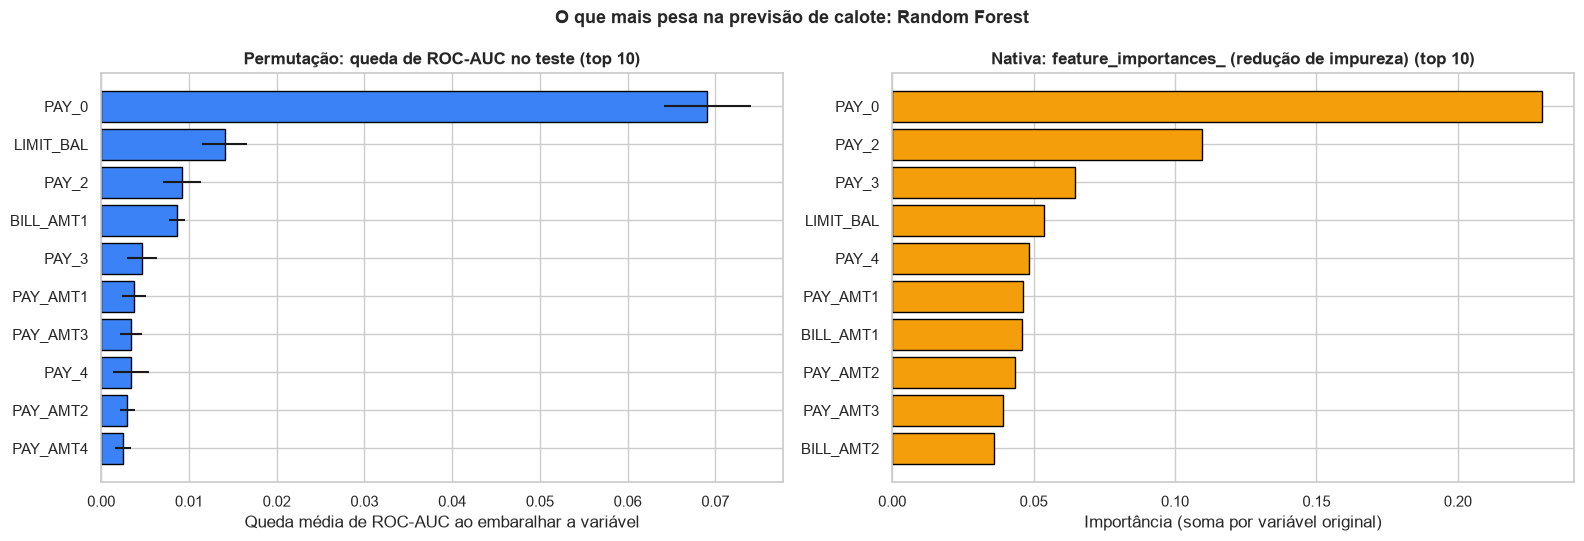

In [19]:
paineis = 2 if serie_nativa is not None else 1
fig, axes = plt.subplots(1, paineis, figsize=(8 * paineis, 5.5), squeeze=False)
top_perm = df_importancia.head(10).iloc[::-1]
axes[0, 0].barh(top_perm["variavel"], top_perm["importancia_permutacao_media"],
                xerr=top_perm["importancia_permutacao_dp"], color="#3b82f6", edgecolor="black")
axes[0, 0].set_title("Permutação: queda de ROC-AUC no teste (top 10)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Queda média de ROC-AUC ao embaralhar a variável")
if serie_nativa is not None:
    top_nat = df_importancia.sort_values("importancia_nativa", ascending=False).head(10).iloc[::-1]
    axes[0, 1].barh(top_nat["variavel"], top_nat["importancia_nativa"], color="#f59e0b", edgecolor="black")
    axes[0, 1].set_title(f"Nativa: {descricao_nativa} (top 10)", fontsize=12, fontweight="bold")
    axes[0, 1].set_xlabel("Importância (soma por variável original)")
fig.suptitle(f"O que mais pesa na previsão de calote: {modelo_vencedor_nome}", fontsize=13, fontweight="bold")
plt.tight_layout()
salvar_figura(fig, "importancia_atributos.png")

In [20]:
ranking_perm = df_importancia["variavel"].tolist()
texto_importancia = (
    f"Ranking por permutação: {', '.join(ranking_perm[:5])} são as 5 variáveis que mais pesam. "
    f"A mais importante, {ranking_perm[0]}, derruba a ROC-AUC em "
    f"{df_importancia['importancia_permutacao_media'].iloc[0]:.3f} quando embaralhada."
)
if serie_nativa is not None:
    ranking_nativo = serie_nativa.sort_values(ascending=False)
    texto_importancia += (
        f" Na medida nativa ({descricao_nativa}), a ordem é "
        f"{', '.join(ranking_nativo.index[:5])}; {ranking_nativo.index[0]} responde por "
        f"{ranking_nativo.iloc[0] / ranking_nativo.sum():.0%} da importância total."
    )
texto_importancia += (
    " Referência da revisão: PAY_0 em primeiro (cerca de 22%), seguido de PAY_2 a PAY_5. "
    + ("O resultado confirma PAY_0 como variável mais importante."
       if ranking_perm[0] == "PAY_0" else
       f"Aqui a primeira posição por permutação é {ranking_perm[0]}, e não PAY_0.")
)
print(texto_importancia)

Ranking por permutação: PAY_0, LIMIT_BAL, PAY_2, BILL_AMT1, PAY_3 são as 5 variáveis que mais pesam. A mais importante, PAY_0, derruba a ROC-AUC em 0.069 quando embaralhada. Na medida nativa (feature_importances_ (redução de impureza)), a ordem é PAY_0, PAY_2, PAY_3, LIMIT_BAL, PAY_4; PAY_0 responde por 23% da importância total. Referência da revisão: PAY_0 em primeiro (cerca de 22%), seguido de PAY_2 a PAY_5. O resultado confirma PAY_0 como variável mais importante.


---
## 9. Resultados para o time técnico
Resumo gerado a partir dos números calculados acima (nada escrito à mão).

In [21]:
linha_vencedor_cv = df_cv[df_cv["vencedor"]].iloc[0]
print("Comparação na validação cruzada (só treino, melhores hiperparâmetros):")
print(df_cv[["modelo", "roc_auc_media", "roc_auc_dp", "pr_auc_media", "recall_media", "precisao_media",
             "f1_media", "melhores_parametros"]].round(4).to_string(index=False))
print(
    f"\n- Vencedor: {modelo_vencedor_nome} ({justificativa_vencedor})\n"
    f"- Hiperparâmetros finais: {parametros_legiveis(parametros_finais)} "
    f"(atributos sensíveis usados: {usar_sensiveis}).\n"
    f"- Corte de decisão: {LIMIAR:.2f} (menor custo na razão FN:FP = {RAZAO_BASE:g}:1, hipótese didática).\n"
    f"- Teste (uso único, {len(y_test)} clientes): ROC-AUC {aval_final['roc_auc']:.4f} "
    f"(CV: {auc_cv_final:.4f}; chute: {aval_chute['roc_auc']:.4f}), recall {aval_final['recall']:.4f}, "
    f"precisão {aval_final['precisao']:.4f}, F1 {aval_final['f1']:.4f}, acurácia {aval_final['acuracia']:.4f}.\n"
    f"- A ROC-AUC do teste ficou {aval_final['roc_auc'] - auc_cv_final:+.4f} em relação à CV: "
    + ("dentro de 2 desvios-padrão da CV, ou seja, a estimativa feita só com o treino era confiável."
       if abs(aval_final['roc_auc'] - auc_cv_final) <= 2 * linha_cv_final['roc_auc_dp'] else
       "fora de 2 desvios-padrão da CV; vale investigar diferença entre treino e teste.")
    + f"\n- {texto_importancia}"
)

bordas = []
for nome, grade in GRADES.items():
    for chave, valores in grade.items():
        escolhido = melhores_parametros[nome][chave]
        # Só hiperparâmetros numéricos; None (sem limite) já é o extremo possível
        numerico = isinstance(escolhido, (int, float)) and not isinstance(escolhido, bool)
        if len(valores) > 1 and numerico and escolhido in (valores[0], valores[-1]):
            bordas.append(f"{nome}: {chave.replace('classificador__', '')} = {escolhido}")
print("- Melhor valor na borda da grade (valores além dela não testados): "
      + ("; ".join(bordas) if bordas else "nenhum."))

Comparação na validação cruzada (só treino, melhores hiperparâmetros):
             modelo  roc_auc_media  roc_auc_dp  pr_auc_media  recall_media  precisao_media  f1_media                                              melhores_parametros
 Chute (referência)         0.5000      0.0000        0.2212        0.0000          0.0000    0.0000                                                               {}
Regressão Logística         0.7276      0.0127        0.5045        0.6508          0.3815    0.4809                                                      {'C': 10.0}
                KNN         0.7592      0.0094        0.5167        0.2616          0.6644    0.3753                       {'n_neighbors': 301, 'weights': 'uniform'}
  Árvore de Decisão         0.7645      0.0060        0.5224        0.6316          0.4472    0.5233                        {'max_depth': 8, 'min_samples_leaf': 500}
      Random Forest         0.7857      0.0053        0.5576        0.6180          0.4871    0.544

---
## 10. Resultados para o negócio
Mesma informação, em linguagem de negócio.

In [22]:
print(
    f"1. Dá para prever? Sim, de forma útil mas não perfeita. Ordenando os clientes pelo escore do "
    f"modelo, um cliente que vai atrasar fica acima de um que vai pagar em {aval_final['roc_auc']:.0%} "
    f"das comparações (o chute fica em 50%).\n"
    f"2. Na prática (6.000 clientes que o modelo nunca viu, corte {br(LIMIAR)}): de {aval_final['VP'] + aval_final['FN']} "
    f"clientes que atrasaram, o modelo avisou {aval_final['VP']} ({aval_final['recall']:.0%}) e deixou passar "
    f"{aval_final['FN']}. Dos {aval_final['VP'] + aval_final['FP']} clientes marcados como risco, "
    f"{aval_final['VP']} atrasaram de fato ({aval_final['precisao']:.0%}); os outros {aval_final['FP']} "
    f"eram bons pagadores incomodados.\n"
    f"3. O que mais leva ao calote: {ranking_perm[0]} (status de pagamento do mês mais recente) é "
    f"de longe o sinal mais forte, seguido de {', '.join(ranking_perm[1:4])}. Quem já está atrasando "
    f"tende a continuar atrasando.\n"
    f"4. Corte: {br(LIMIAR)}, supondo que deixar passar um caloteiro custa {RAZAO_BASE:g} vezes mais que "
    f"incomodar um bom pagador. Se a área de crédito estimar outra razão, o corte muda (ver "
    f"limiar_sensibilidade_custo.csv): quanto mais caro o calote, menor o corte e mais clientes "
    f"marcados.\n"
    f"5. Sexo, idade e estado civil: "
    + ("não são usados pelo modelo de produção; retirá-los quase não muda a qualidade do modelo."
       if not usar_sensiveis else "são usados pelo modelo de produção (decisão do grupo).")
)

1. Dá para prever? Sim, de forma útil mas não perfeita. Ordenando os clientes pelo escore do modelo, um cliente que vai atrasar fica acima de um que vai pagar em 77% das comparações (o chute fica em 50%).
2. Na prática (6.000 clientes que o modelo nunca viu, corte 0,50): de 1327 clientes que atrasaram, o modelo avisou 800 (60%) e deixou passar 527. Dos 1665 clientes marcados como risco, 800 atrasaram de fato (48%); os outros 865 eram bons pagadores incomodados.
3. O que mais leva ao calote: PAY_0 (status de pagamento do mês mais recente) é de longe o sinal mais forte, seguido de LIMIT_BAL, PAY_2, BILL_AMT1. Quem já está atrasando tende a continuar atrasando.
4. Corte: 0,50, supondo que deixar passar um caloteiro custa 3 vezes mais que incomodar um bom pagador. Se a área de crédito estimar outra razão, o corte muda (ver limiar_sensibilidade_custo.csv): quanto mais caro o calote, menor o corte e mais clientes marcados.
5. Sexo, idade e estado civil: não são usados pelo modelo de produção

---
## 11. Limitações
- **Desbalanceamento:** só ~22% dos clientes atrasam. Compensamos com `class_weight="balanced"`
  e com métricas adequadas (ROC-AUC, recall, precisão, F1), mas a classe minoritária continua
  mais difícil de acertar.
- **Escore não calibrado:** com `class_weight="balanced"`, o escore do modelo superestima a
  chance real de atraso. Ele serve para **ordenar** clientes por risco, não como percentual
  literal. Calibrar (por exemplo, `CalibratedClassifierCV`) fica como trabalho futuro.
- **Dados de Taiwan, 2005:** outro país, outra moeda, outra época e um único banco. Os padrões
  podem não valer para clientes brasileiros de hoje; seria preciso revalidar com dados locais e
  monitorar a mudança dos dados ao longo do tempo.
- **Atributos sensíveis:** retirar sexo, idade e estado civil não garante um modelo justo, pois
  outras variáveis podem carregar parte dessa informação; `EDUCATION` continua no modelo. Não
  fizemos auditoria de justiça por grupo.
- **Custo hipotético:** a razão 3:1 entre o custo de um falso negativo e o de um falso positivo é
  uma hipótese didática, não um dado do banco. O corte ideal depende dessa razão.
- **KNN sem balanceamento:** o `KNeighborsClassifier` não aceita `class_weight`; por isso a
  comparação principal usa ROC-AUC, que não depende do corte, mas recall, precisão e F1 do KNN
  no corte 0,50 não são comparáveis aos dos demais.
- **Grade de hiperparâmetros pequena:** para caber em poucos minutos. O resumo técnico (etapa 9)
  lista os hiperparâmetros cujo melhor valor ficou na borda da grade; além dela, nada foi testado.
- **Uso na API:** o modelo foi treinado com os 6 meses reais de histórico. Quando o formulário
  envia só o mês mais recente, a API estima os outros meses, o que reduz a confiança da previsão
  (a resposta da API avisa quando isso acontece).